<a href="https://colab.research.google.com/github/lkipo/medIA-cmi/blob/master/regresion_intro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Adestrar unha rede de regresión

Neste caderno imos ensinarlle a unha rede neuronal a **aprender unha función a partir de exemplos**.
Antes de falar de imaxes, queremos ver o mecanismo máis puro do adestramento:

1. temos **datos** (parellas entrada–saída),
2. temos un **modelo** con parámetros aleatorios,
3. medimos o **erro** (a perda) e axustamos os parámetros para reducilo.

A diferenza de MNIST (clasificación: *que díxito é?*), aquí facemos **regresión**: o modelo predí un
**número continuo**. En imaxe médica sería, por exemplo, estimar o volume dun órgano, a idade ósea ou a
concentración dun marcador.

Todo corre en segundos, con ou sen GPU.

## Instalación de dependencias

Comproba que estean todas as bibliotecas necesarias e instala automaticamente as que falten (en Colab xa vén case todo instalado).

In [1]:
import importlib.util, subprocess, sys

# (nome para importar, nome do paquete en pip)
REQUISITOS = [("numpy", "numpy"), ("matplotlib", "matplotlib"), ("torch", "torch")]

faltan = [pip for mod, pip in REQUISITOS if importlib.util.find_spec(mod) is None]
if faltan:
    print("Instalando:", faltan)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltan])
else:
    print("Todas as dependencias están instaladas.")

Todas as dependencias están instaladas.


## 0. Preparación

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)
np.random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| dispositivo:", device)

PyTorch: 2.8.0 | dispositivo: cpu


## 1. Datos sintéticos cunha relación coñecida

Xeramos os datos nós mesmos, así **sabemos a «verdade»** e podemos comprobar se o modelo a recupera:

$$ y = \sin(x) + 0.3\,x + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0,\,0.15^2) $$

- $\sin(x) + 0.3x$ é a relación real (non lineal: unha ondulación sobre unha tendencia).
- $\varepsilon$ é **ruído** aleatorio, como o que hai en calquera medición real.

Tomamos 200 puntos en $x \in [-3, 3]$ e reservamos o 20 % para **validación** (datos que o modelo non ve
ao adestrar).

adestramento: (160, 1) | validación: (40, 1)


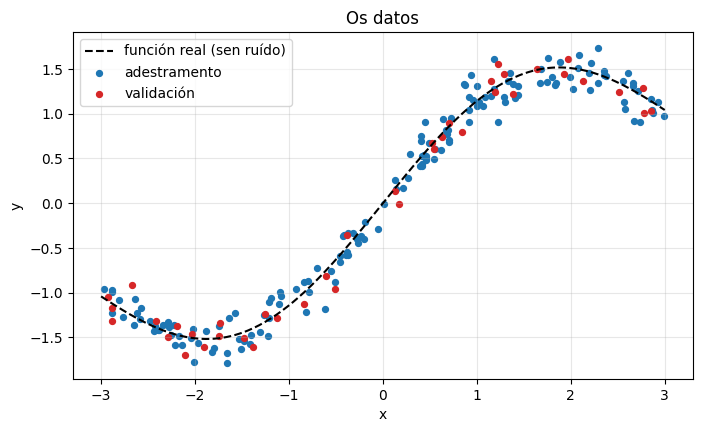

In [3]:
def funcion_real(x):
    return np.sin(x) + 0.3 * x

n = 200
x = np.random.uniform(-3, 3, size=(n, 1)).astype(np.float32)
y = (funcion_real(x) + np.random.normal(0, 0.15, size=(n, 1))).astype(np.float32)

# división adestramento / validación
perm = np.random.permutation(n)
n_val = int(0.2 * n)
idx_val, idx_tr = perm[:n_val], perm[n_val:]

x_tr, y_tr = torch.tensor(x[idx_tr]).to(device), torch.tensor(y[idx_tr]).to(device)
x_val, y_val = torch.tensor(x[idx_val]).to(device), torch.tensor(y[idx_val]).to(device)
print("adestramento:", tuple(x_tr.shape), "| validación:", tuple(x_val.shape))

xs = np.linspace(-3, 3, 400, dtype=np.float32).reshape(-1, 1)
plt.figure(figsize=(8, 4.5))
plt.plot(xs, funcion_real(xs), "k--", label="función real (sen ruído)")
plt.scatter(x[idx_tr], y[idx_tr], s=18, label="adestramento")
plt.scatter(x[idx_val], y[idx_val], s=18, c="C3", label="validación")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Os datos")
plt.show()

## 2. O modelo

Unha rede pequena: **1 entrada → 32 neuronas → 32 neuronas → 1 saída**.

- Cada `nn.Linear` calcula $W x + b$ (combinación ponderada máis sesgo).
- `nn.ReLU` é a **activación**: introduce a non-linearidade. Sen ela, apilar capas lineais daría
  igualmente unha única función lineal.
- A saída é **unha soa neurona sen activación**, porque queremos un número real calquera.

Sequential(
  (0): Linear(in_features=1, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
Parámetros adestrables: 1153


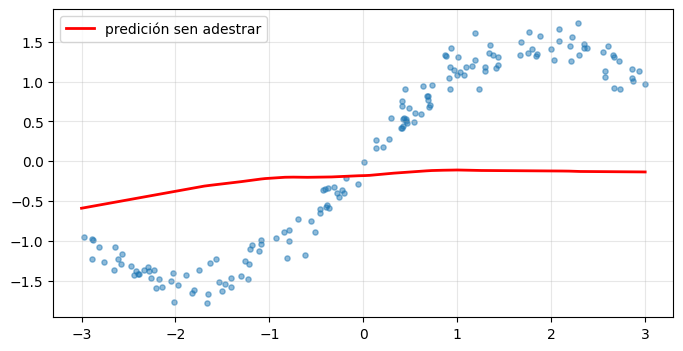

In [4]:
def crear_modelo():
    return nn.Sequential(
        nn.Linear(1, 32), nn.ReLU(),
        nn.Linear(32, 32), nn.ReLU(),
        nn.Linear(32, 1),
    ).to(device)

modelo = crear_modelo()
print(modelo)
print("Parámetros adestrables:", sum(p.numel() for p in modelo.parameters()))

# Antes de adestrar: os pesos son aleatorios, así que a predición é un disparate
with torch.no_grad():
    pred0 = modelo(torch.tensor(xs).to(device)).cpu().numpy()
plt.figure(figsize=(8, 4))
plt.scatter(x[idx_tr], y[idx_tr], s=14, alpha=0.5)
plt.plot(xs, pred0, "r", lw=2, label="predición sen adestrar")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 3. O bucle de adestramento

A **perda** que usamos é o **erro cadrático medio (MSE)**:

$$ \text{MSE} = \frac{1}{N}\sum_i (\hat y_i - y_i)^2 $$

Cada iteración repite catro pasos:

1. **forward**: calcular as predicións $\hat y$,
2. **perda**: medir canto se equivocan,
3. **backward**: calcular o gradiente da perda respecto de cada peso (retropropagación),
4. **actualización**: mover os pesos un chisco na dirección que reduce a perda.

Como o conxunto é minúsculo, usamos **todos os datos de golpe** en cada paso (*full batch*).

In [5]:
def adestrar(modelo, epocas=1000, lr=1e-2, verbose=True):
    perda_fn = nn.MSELoss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    hist = {"tr": [], "val": []}

    for ep in range(1, epocas + 1):
        modelo.train()
        pred = modelo(x_tr)                 # 1. forward
        perda = perda_fn(pred, y_tr)        # 2. perda
        optimizador.zero_grad()
        perda.backward()                    # 3. backward
        optimizador.step()                  # 4. actualización

        modelo.eval()
        with torch.no_grad():
            perda_val = perda_fn(modelo(x_val), y_val)
        hist["tr"].append(perda.item()); hist["val"].append(perda_val.item())

        if verbose and (ep % 200 == 0 or ep == 1):
            print(f"época {ep:4d} | perda adestr. {perda.item():.4f} | perda valid. {perda_val.item():.4f}")
    return hist

hist = adestrar(modelo)

época    1 | perda adestr. 1.1788 | perda valid. 0.7664
época  200 | perda adestr. 0.0187 | perda valid. 0.0201
época  400 | perda adestr. 0.0182 | perda valid. 0.0205


época  600 | perda adestr. 0.0179 | perda valid. 0.0213
época  800 | perda adestr. 0.0171 | perda valid. 0.0211
época 1000 | perda adestr. 0.0171 | perda valid. 0.0220


## 4. Que aprendeu? Curva de perda e axuste

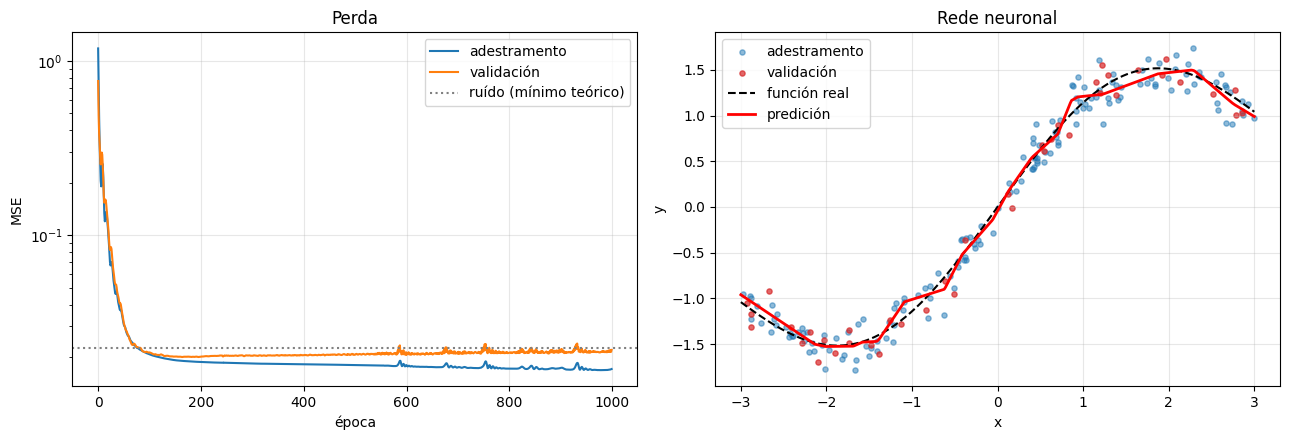

In [6]:
def mostrar_axuste(modelo, hist, titulo="Rede neuronal"):
    modelo.eval()
    with torch.no_grad():
        pred = modelo(torch.tensor(xs).to(device)).cpu().numpy()

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ax[0].semilogy(hist["tr"], label="adestramento")
    ax[0].semilogy(hist["val"], label="validación")
    ax[0].axhline(0.15**2, color="gray", ls=":", label="ruído (mínimo teórico)")
    ax[0].set_xlabel("época"); ax[0].set_ylabel("MSE"); ax[0].legend(); ax[0].grid(alpha=0.3)
    ax[0].set_title("Perda")

    ax[1].scatter(x[idx_tr], y[idx_tr], s=14, alpha=0.5, label="adestramento")
    ax[1].scatter(x[idx_val], y[idx_val], s=14, c="C3", alpha=0.7, label="validación")
    ax[1].plot(xs, funcion_real(xs), "k--", label="función real")
    ax[1].plot(xs, pred, "r", lw=2, label="predición")
    ax[1].set_xlabel("x"); ax[1].set_ylabel("y"); ax[1].legend(); ax[1].grid(alpha=0.3)
    ax[1].set_title(titulo)
    plt.tight_layout(); plt.show()

mostrar_axuste(modelo, hist)

Observa:

- A perda **cae rapidamente** e despois se aplana: o modelo xa recuperou o patrón.
- Non chega a cero, e **non debe**: o ruído é irreducible. A liña punteada gris
  ($0.15^2 \approx 0.0225$) é o mellor MSE que se pode esperar.
- A curva predita segue a función real, **non os puntos ruidosos**. Iso é xeneralizar.

## 5. Por que necesitamos a non-linearidade?

Probemos a mesma configuración, pero **sen ReLU**: tres capas lineais seguidas.

MSE validación | con ReLU: 0.0220 | sen ReLU: 0.2285


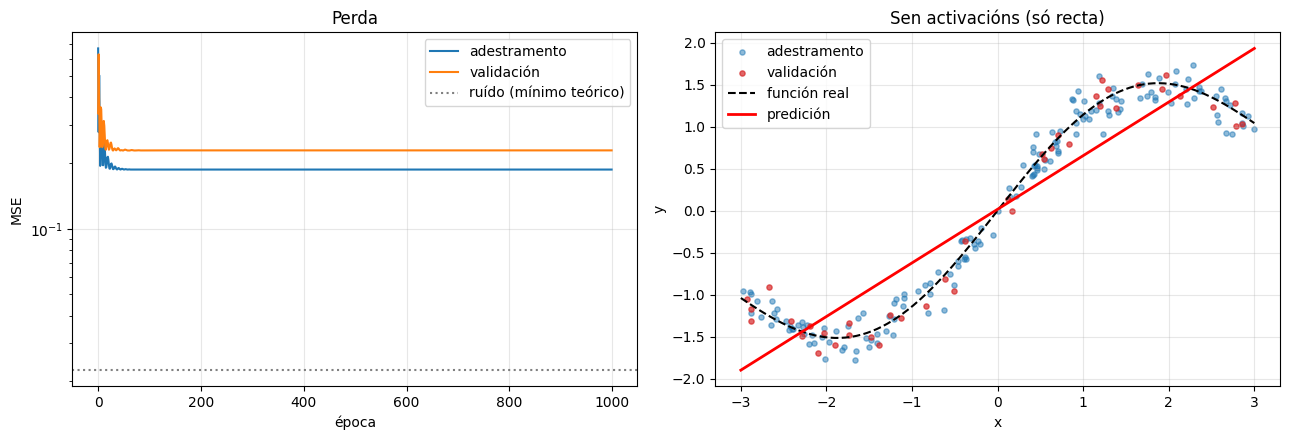

In [7]:
torch.manual_seed(0)
modelo_lin = nn.Sequential(nn.Linear(1, 32), nn.Linear(32, 32), nn.Linear(32, 1)).to(device)
hist_lin = adestrar(modelo_lin, verbose=False)
print(f"MSE validación | con ReLU: {hist['val'][-1]:.4f} | sen ReLU: {hist_lin['val'][-1]:.4f}")
mostrar_axuste(modelo_lin, hist_lin, "Sen activacións (só recta)")

Sen activacións, composición de funcións lineais é outra función lineal: o modelo só pode debuxar unha
**recta**, por moitas capas que teña. Da mesma forma, unha CNN sen activacións non podería detectar
estruturas complexas nunha imaxe.

## 6. Sobreaxuste (overfitting) e extrapolación

Dúas trampas habituais en imaxe médica, que tamén se ven aquí:

**a) Adestrar demasiado un modelo grande con poucos datos.** Usamos só 20 puntos e unha rede máis grande.

**b) Predicir fóra do rango visto.** O modelo nunca viu $x>3$.

MSE adestramento: 0.00038 | MSE validación: 0.06222


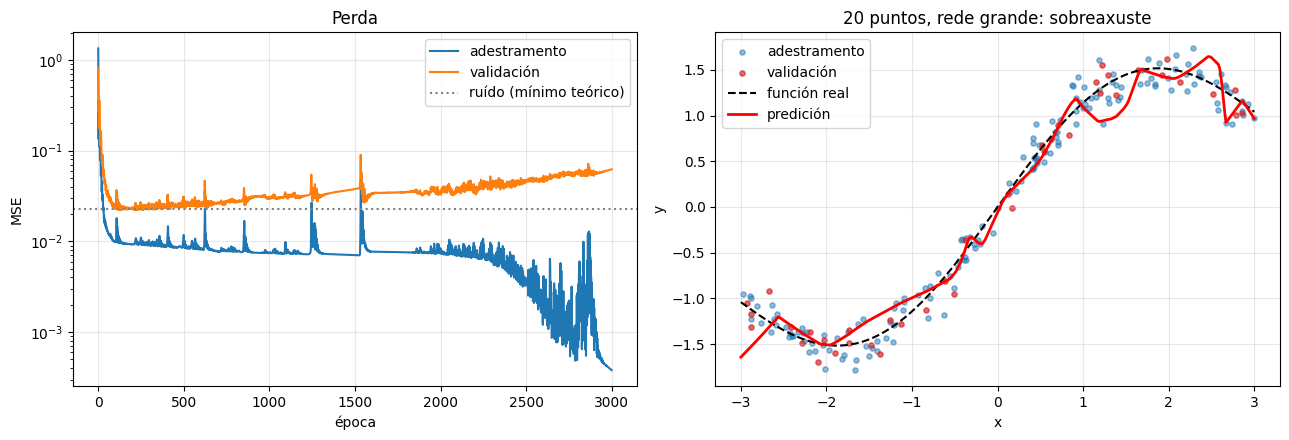

In [8]:
# a) Pouquísimos datos + rede grande + moitas épocas
torch.manual_seed(1)
pocos = idx_tr[:20]
x_tr_full, y_tr_full = x_tr, y_tr
x_tr, y_tr = torch.tensor(x[pocos]).to(device), torch.tensor(y[pocos]).to(device)

grande = nn.Sequential(nn.Linear(1, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(),
                       nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 1)).to(device)
hist_g = adestrar(grande, epocas=3000, lr=5e-3, verbose=False)
print(f"MSE adestramento: {hist_g['tr'][-1]:.5f} | MSE validación: {hist_g['val'][-1]:.5f}")
mostrar_axuste(grande, hist_g, "20 puntos, rede grande: sobreaxuste")

x_tr, y_tr = x_tr_full, y_tr_full   # restauramos os datos

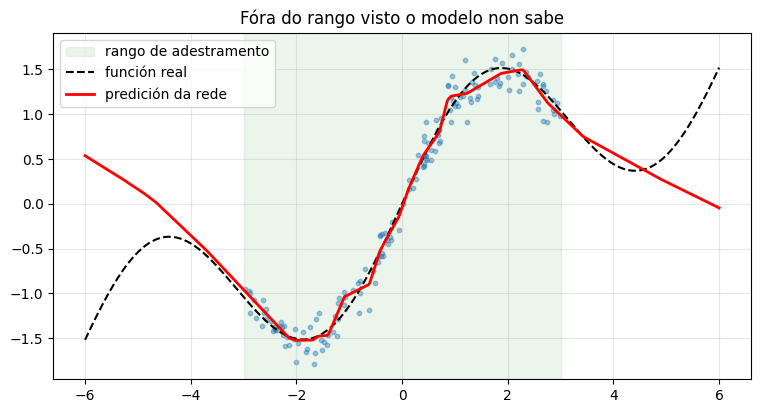

In [9]:
# b) Extrapolación: predicimos en [-6, 6], pero só adestramos en [-3, 3]
xs_ext = np.linspace(-6, 6, 600, dtype=np.float32).reshape(-1, 1)
modelo.eval()
with torch.no_grad():
    pred_ext = modelo(torch.tensor(xs_ext).to(device)).cpu().numpy()

plt.figure(figsize=(9, 4.5))
plt.axvspan(-3, 3, color="green", alpha=0.08, label="rango de adestramento")
plt.plot(xs_ext, funcion_real(xs_ext), "k--", label="función real")
plt.plot(xs_ext, pred_ext, "r", lw=2, label="predición da rede")
plt.scatter(x[idx_tr], y[idx_tr], s=10, alpha=0.4)
plt.legend(); plt.grid(alpha=0.3); plt.title("Fóra do rango visto o modelo non sabe")
plt.show()

**Mensaxes clave**

- A perda de adestramento baixando **non** garante un bo modelo: hai que mirar a **validación**.
- Un modelo só é fiable no tipo de datos que viu. Isto é o **cambio de dominio** (*domain shift*): un
  modelo adestrado cun escáner ou protocolo pode fallar cun distinto.

## 7. Mirando dentro: o gradiente a man

`loss.backward()` non é maxia. Para comprobalo, tomamos o modelo máis simple posible,
$\hat y = w\,x$, cun só dato, e comparamos o gradiente de PyTorch coa derivada calculada a man.

Con $L = (w x - y)^2$, a regra da cadea dá $\dfrac{\partial L}{\partial w} = 2\,(w x - y)\,x$.

In [10]:
w = torch.tensor(0.5, requires_grad=True)
x0, y0 = 2.0, 3.0

L = (w * x0 - y0) ** 2
L.backward()

a_man = 2 * (w.item() * x0 - y0) * x0
print(f"gradiente de PyTorch (autograd): {w.grad.item():.4f}")
print(f"gradiente calculado a man:       {a_man:.4f}")

# Unha actualización de descenso de gradiente
lr = 0.1
w_novo = w.item() - lr * w.grad.item()
print(f"w pasa de {w.item():.2f} a {w_novo:.2f}  (o óptimo é w = y/x = {y0/x0:.2f})")

gradiente de PyTorch (autograd): -8.0000
gradiente calculado a man:       -8.0000
w pasa de 0.50 a 1.30  (o óptimo é w = y/x = 1.50)


## 8. Para probar

1. Cambia o **learning rate** (`1e-4`, `1e-2`, `1`). Que lle pasa á curva de perda?
2. Cambia a activación a `nn.Tanh()` ou `nn.Sigmoid()`. Como cambia a forma da predición?
3. Aumenta o ruído (`0.15` → `0.5`). Que lle pasa ao MSE mínimo alcanzable?
4. Reduce as neuronas ocultas a 2 ou 4. Cantas necesita o modelo para captar a ondulación?
5. Cambia a función real (por exemplo `x**2` ou `np.abs(x)`) e comproba se a rede a aprende.

**Seguinte paso:** na clasificación (MNIST) a saída eran 10 puntuacións; na **segmentación** a rede
fai unha predición **por cada píxel**. É o tema do seguinte caderno.